# Notebook 2 — EMO-FAR multimodal fusion on CMU-MOSEI (text + audio + video)

**Goal of this notebook (execution demo):**
1. Re-implement the paper's **RMSR** fusion exactly as written (Eq. 9–14) and show its two technical problems:
   - **Eq. 12:** softmax over sigmoid scores → a modality's weight can never go below ≈ 0.155, so a missing/noisy modality is never switched off.
   - **Eq. 13:** attention between two single vectors → softmax over one number is always 1 → it is just a linear layer.
2. Build our **fixed fusion**: token-level cross-attention, masked gating (missing modality → weight exactly 0) and modality dropout.
3. Compare 4 models and test robustness when audio, video or text are missing (0 / 30 / 50 / 70 %).

**Data:** the MMSA release of CMU-MOSEI (`aligned_50.pkl`): per clip, 50 word-aligned steps of BERT text features (768),
COVAREP audio features and Facet visual features, with the official train/valid/test split.

**Runtime:** Colab → Runtime → Change runtime type → **GPU** and **High-RAM** (the MOSEI file is 4.4 GB). Run top to bottom.

## 0. Setup

In [1]:
import os, sys, time, random, pickle, warnings
warnings.filterwarnings("ignore", category=UserWarning)
IN_COLAB = "google.colab" in sys.modules
TEST_MODE = os.environ.get("EMOFAR_TEST") == "1"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Mounted at /content/drive
Device: cpu


## 1. Settings

In [2]:
DATA_PATH = "/content/drive/MyDrive/datasets/CMU-MOSEI/aligned_50.pkl"
# DATA_PATH = "/content/drive/MyDrive/datasets/CMU-MOSI/Processed/aligned_50.pkl"   # smaller dataset (2,199 clips)
OUT_DIR = "/content/drive/MyDrive/emofar_results"
D_MODEL = 128        # size every modality is projected to
EPOCHS = 30
PATIENCE = 6         # stop if validation macro-F1 does not improve for this many epochs
BATCH_SIZE = 64
LR = 5e-4
MOD_DROPOUT = 0.3    # chance of hiding each modality during training (our fixed model)
SEEDS = [42]         # use [42, 43, 44] for the final report
if TEST_MODE:
    DATA_PATH, OUT_DIR, EPOCHS = os.environ["EMOFAR_MOSI"], os.environ["EMOFAR_OUT"], int(os.environ.get("EMOFAR_EPOCHS", 3))
os.makedirs(OUT_DIR, exist_ok=True)
LABELS = ["negative", "neutral", "positive"]
MODS = ["text", "audio", "vision"]

## 2. Load the features
- **Mask:** which of the 50 steps are real words (the rest is padding), taken from the BERT attention mask.
- **Cleaning:** replace NaN/∞ in audio and video with 0, then standardise each feature with **training-set** mean and std.
- **Labels:** sentiment score < 0 → negative, = 0 → neutral, > 0 → positive.

In [3]:
t0 = time.time()
with open(DATA_PATH, "rb") as f:
    raw = pickle.load(f)
print(f"Loaded in {time.time() - t0:.0f}s")

def prep(split):
    d = raw[split]
    mask = d["text_bert"][:, 1, :].astype(bool)                        # (N, 50) real-word steps
    feats = {"text": d["text"].astype(np.float32),
             "audio": np.nan_to_num(d["audio"].astype(np.float32), nan=0.0, posinf=0.0, neginf=0.0),
             "vision": np.nan_to_num(d["vision"].astype(np.float32), nan=0.0, posinf=0.0, neginf=0.0)}
    score = d["regression_labels"].astype(np.float32)
    y = np.where(score < 0, 0, np.where(score == 0, 1, 2))
    return {"feats": feats, "mask": mask, "y": y, "score": score, "raw_text": d["raw_text"]}

data = {s: prep(s) for s in ["train", "valid", "test"]}
del raw

for m in ["audio", "vision"]:                                           # standardise with train statistics
    tr = data["train"]["feats"][m][data["train"]["mask"]]
    mu, sd = tr.mean(0), tr.std(0) + 1e-6
    for s in data:
        x = (data[s]["feats"][m] - mu) / sd
        data[s]["feats"][m] = np.clip(x, -10, 10) * data[s]["mask"][..., None]

DIMS = {m: data["train"]["feats"][m].shape[-1] for m in MODS}
print("Feature sizes:", DIMS)
for s in data:
    counts = np.bincount(data[s]["y"], minlength=3)
    print(f"{s:5s}: {len(data[s]['y']):6,} clips | " + " / ".join(f"{LABELS[i]} {counts[i]:,}" for i in range(3)))

Loaded in 70s
Feature sizes: {'text': 768, 'audio': 74, 'vision': 35}
train: 16,326 clips | negative 4,738 / neutral 3,540 / positive 8,048
valid:  1,871 clips | negative 506 / neutral 433 / positive 932
test :  4,659 clips | negative 1,350 / neutral 1,025 / positive 2,284


## 3. The four models
| Model | What it is |
|---|---|
| **M1 Text-only** | average of text features → classifier |
| **M2 EMO-FAR RMSR (as written)** | pooled vectors, `q = σ(u·z)`, `γ = softmax(q)`, single-vector attention (Eq. 9–14) |
| **M3 Fixed fusion** | token-level cross-attention + **masked** gating (missing → weight 0) |
| **M4 Fixed fusion + modality dropout** | M3 trained while randomly hiding text/audio/video (30 % each) |

In [4]:
def masked_mean(x, mask):
    m = mask.unsqueeze(-1).float()
    return (x * m).sum(1) / m.sum(1).clamp(min=1)

class TextOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(DIMS["text"], D_MODEL), nn.ReLU(), nn.Dropout(0.2), nn.Linear(D_MODEL, 3))
    def forward(self, x, mask, avail, return_gate=False):
        out = self.net(masked_mean(x["text"], mask))
        return (out, None) if return_gate else out

class PaperRMSR(nn.Module):
    """EMO-FAR's RMSR exactly as the equations are written."""
    def __init__(self):
        super().__init__()
        self.proj = nn.ModuleDict({m: nn.Linear(DIMS[m], D_MODEL) for m in MODS})          # Eq. 10
        self.u = nn.ParameterDict({m: nn.Parameter(torch.randn(D_MODEL) * 0.05) for m in MODS})  # Eq. 11
        self.Wq, self.Wk, self.Wv = (nn.Linear(D_MODEL, D_MODEL) for _ in range(3))
        self.cls = nn.Sequential(nn.Dropout(0.2), nn.Linear(D_MODEL, 3))
    def forward(self, x, mask, avail, return_gate=False):
        z = {m: self.proj[m](masked_mean(x[m], mask)) for m in MODS}                     # one vector per modality
        q = torch.stack([torch.sigmoid((z[m] * self.u[m]).sum(-1)) for m in MODS], -1)   # Eq. 11, values in (0,1)
        gamma = q.softmax(-1)                                                             # Eq. 12
        att = {}
        for m in ["audio", "vision"]:                                                     # Eq. 13
            score = (self.Wq(z["text"]) * self.Wk(z[m])).sum(-1, keepdim=True) / D_MODEL ** 0.5
            att[m] = score.softmax(-1) * self.Wv(z[m])                                    # softmax over 1 number = 1
        h = gamma[:, :1] * z["text"] + gamma[:, 1:2] * att["audio"] + gamma[:, 2:] * att["vision"]   # Eq. 14
        out = self.cls(h)
        return (out, gamma) if return_gate else out

class FixedFusion(nn.Module):
    """Our fix: token-level cross-attention + masked gating."""
    def __init__(self):
        super().__init__()
        self.proj = nn.ModuleDict({m: nn.Sequential(nn.Linear(DIMS[m], D_MODEL), nn.LayerNorm(D_MODEL)) for m in MODS})
        self.xattn = nn.ModuleDict({m: nn.MultiheadAttention(D_MODEL, 4, batch_first=True, dropout=0.1)
                                    for m in ["audio", "vision"]})
        self.gate = nn.Linear(3 * D_MODEL, 3)
        self.cls = nn.Sequential(nn.Dropout(0.2), nn.Linear(D_MODEL, D_MODEL), nn.ReLU(), nn.Linear(D_MODEL, 3))
    def forward(self, x, mask, avail, return_gate=False):
        p = {m: self.proj[m](x[m]) * avail[:, i, None, None] for i, m in enumerate(MODS)}   # hidden modality -> zeros
        h = {"text": masked_mean(p["text"], mask)}
        for m in ["audio", "vision"]:            # each text token (query) looks at every audio/video step (keys)
            attended, _ = self.xattn[m](p["text"], p[m], p[m], key_padding_mask=~mask)
            h[m] = masked_mean(attended + p[m], mask)
        logits = self.gate(torch.cat([h[m] for m in MODS], -1))
        logits = logits.masked_fill(avail == 0, float("-inf"))                              # missing -> weight 0
        w = logits.softmax(-1)
        fused = sum(w[:, i:i + 1] * h[m] for i, m in enumerate(MODS))
        out = self.cls(fused)
        return (out, w) if return_gate else out

MODELS = {"M1 Text-only": (TextOnly, 0.0),
          "M2 EMO-FAR RMSR (as written)": (PaperRMSR, 0.0),
          "M3 Fixed fusion": (FixedFusion, 0.0),
          "M4 Fixed fusion + modality dropout": (FixedFusion, MOD_DROPOUT)}

## 4. Training and evaluation
**Availability vector** `avail = [text, audio, vision]` (1 = present, 0 = hidden). Hidden features are set to zero.
For modality dropout and the robustness test we hide modalities at random, always keeping at least one.
**Metrics:** accuracy, macro-F1, **Acc-2** (positive vs negative on clips whose score ≠ 0, the standard MOSEI metric), ECE.

In [5]:
from sklearn.metrics import f1_score, accuracy_score

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def sample_avail(n, rates, rng):
    """rates = (p_text, p_audio, p_vision): chance each modality is hidden. At least one stays."""
    avail = (rng.rand(n, 3) >= np.array(rates)).astype(np.float32)
    none_left = avail.sum(1) == 0
    avail[none_left, rng.randint(0, 3, none_left.sum())] = 1
    return avail

def to_batch(d, idx, avail):
    x = {m: torch.from_numpy(d["feats"][m][idx]).to(DEVICE) for m in MODS}
    for i, m in enumerate(MODS):
        x[m] = x[m] * torch.from_numpy(avail[:, i]).to(DEVICE)[:, None, None]
    return x, torch.from_numpy(d["mask"][idx]).to(DEVICE), torch.from_numpy(avail).to(DEVICE)

@torch.no_grad()
def predict(model, d, rates=(0, 0, 0), seed=0):
    model.eval(); rng = np.random.RandomState(seed); out = []
    for i in range(0, len(d["y"]), 256):
        idx = np.arange(i, min(i + 256, len(d["y"])))
        x, mask, avail = to_batch(d, idx, sample_avail(len(idx), rates, rng))
        out.append(model(x, mask, avail).softmax(-1).cpu().numpy())
    return np.concatenate(out)

def ece_score(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1); ece = 0.0
    for lo, hi in zip(np.linspace(0, 1, n_bins + 1)[:-1], np.linspace(0, 1, n_bins + 1)[1:]):
        sel = (conf > lo) & (conf <= hi)
        if sel.any():
            ece += sel.mean() * abs((pred[sel] == y[sel]).mean() - conf[sel].mean())
    return float(ece)

def evaluate(probs, d):
    y, pred = d["y"], probs.argmax(1)
    nz = d["score"] != 0
    acc2 = ((probs[nz, 2] > probs[nz, 0]) == (d["score"][nz] > 0)).mean()
    return {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
            "acc2": float(acc2), "ece": ece_score(probs, y)}

def train(name, seed):
    cls, drop = MODELS[name]
    set_seed(seed)
    model = cls().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    counts = np.bincount(data["train"]["y"], minlength=3)
    class_w = torch.tensor(counts.sum() / (3 * counts), dtype=torch.float, device=DEVICE)  # balance classes
    rng = np.random.RandomState(seed); tr = data["train"]
    best, best_state, bad = -1, None, 0
    for ep in range(EPOCHS):
        model.train()
        order = rng.permutation(len(tr["y"]))
        for i in range(0, len(order), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            x, mask, avail = to_batch(tr, idx, sample_avail(len(idx), (drop, drop, drop), rng))
            loss = F.cross_entropy(model(x, mask, avail), torch.from_numpy(tr["y"][idx]).to(DEVICE), weight=class_w)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        val = evaluate(predict(model, data["valid"]), data["valid"])["macro_f1"]
        if val > best:
            best, bad = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    print(f"  {name:38s} best valid macro-F1 = {best:.4f}  (stopped after epoch {ep + 1})")
    return model

## 5. Train all four models

In [6]:
results, trained = [], {}
for name in MODELS:
    for seed in SEEDS:
        model = train(name, seed)
        r = evaluate(predict(model, data["test"]), data["test"]); r.update(model=name, seed=seed)
        results.append(r)
        if seed == SEEDS[0]:
            trained[name] = model
res = pd.DataFrame(results)
res.to_csv(f"{OUT_DIR}/mosei_results_all_seeds.csv", index=False)
summary = res.groupby("model", sort=False)[["accuracy", "macro_f1", "acc2", "ece"]].mean()
summary.to_csv(f"{OUT_DIR}/mosei_results_summary.csv")
summary.round(4)

  M1 Text-only                           best valid macro-F1 = 0.6246  (stopped after epoch 12)
  M2 EMO-FAR RMSR (as written)           best valid macro-F1 = 0.6181  (stopped after epoch 9)
  M3 Fixed fusion                        best valid macro-F1 = 0.6315  (stopped after epoch 12)
  M4 Fixed fusion + modality dropout     best valid macro-F1 = 0.6269  (stopped after epoch 11)


,accuracy,macro_f1,acc2,ece
model,,,,
M1 Text-only,0.6435,0.6268,0.8385,0.0223
M2 EMO-FAR RMSR (as written),0.6527,0.6272,0.8302,0.0222
M3 Fixed fusion,0.6622,0.6263,0.8316,0.0392
M4 Fixed fusion + modality dropout,0.6602,0.6363,0.8327,0.0167


## 6. Robustness: hide modalities at test time
Scenarios: audio+video hidden at 30/50/70 %, and **text** hidden at 30/50/70 % (the paper assumes text is always present).

In [7]:
scenarios = [("all present", (0, 0, 0))]
scenarios += [(f"audio+video hidden {int(r*100)}%", (0, r, r)) for r in (0.3, 0.5, 0.7)]
scenarios += [(f"text hidden {int(r*100)}%", (r, 0, 0)) for r in (0.3, 0.5, 0.7)]
rob = []
for name, model in trained.items():
    for sc, rates in scenarios:
        m = evaluate(predict(model, data["test"], rates, seed=7), data["test"])
        rob.append({"model": name, "scenario": sc, "macro_f1": m["macro_f1"]})
rob_df = pd.DataFrame(rob).pivot(index="scenario", columns="model", values="macro_f1").loc[[s for s, _ in scenarios]]
rob_df.to_csv(f"{OUT_DIR}/mosei_robustness.csv")
rob_df.round(4)

model,M1 Text-only,M2 EMO-FAR RMSR (as written),M3 Fixed fusion,M4 Fixed fusion + modality dropout
scenario,,,,
all present,0.6268,0.6272,0.6263,0.6363
audio+video hidden 30%,0.6268,0.6260,0.6277,0.6355
audio+video hidden 50%,0.6268,0.6276,0.6243,0.6341
audio+video hidden 70%,0.6268,0.6236,0.6261,0.6310
text hidden 30%,0.5202,0.5383,0.5591,0.5705
text hidden 50%,0.4399,0.4896,0.5158,0.5283
text hidden 70%,0.3361,0.4301,0.4625,0.4861


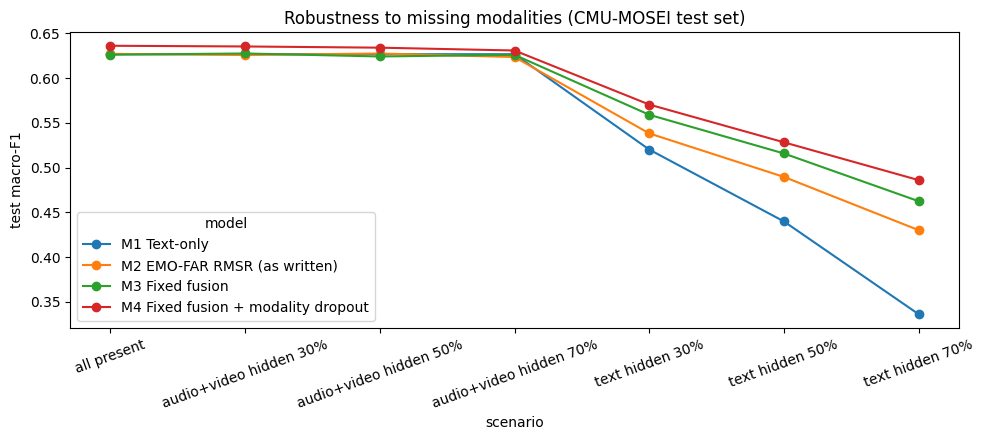

In [8]:
import matplotlib.pyplot as plt
ax = rob_df.plot(marker="o", figsize=(10, 4.5), rot=20)
ax.set_ylabel("test macro-F1"); ax.set_title("Robustness to missing modalities (CMU-MOSEI test set)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/mosei_robustness.png", dpi=150); plt.show()

## 7. Proof of the gating problem (Eq. 12) — on real test data
We hide **audio** for every test clip and look at the weight each model still gives to audio.

In [9]:
d = data["test"]; idx = np.arange(min(512, len(d["y"])))
avail = np.ones((len(idx), 3), dtype=np.float32); avail[:, 1] = 0          # audio hidden
x, mask, av = to_batch(d, idx, avail)
for name in ["M2 EMO-FAR RMSR (as written)", "M4 Fixed fusion + modality dropout"]:
    with torch.no_grad():
        _, w = trained[name].eval()(x, mask, av, return_gate=True)
    w = w.cpu().numpy()
    print(f"{name:38s} audio weight with audio HIDDEN: min {w[:, 1].min():.3f}  mean {w[:, 1].mean():.3f}")
e = np.e
print(f"\nTheory for Eq. 12 with 3 modalities: any weight is always between 1/(1+2e) = {1/(1+2*e):.3f} and e/(e+2) = {e/(e+2):.3f}")
print("Theory for Eq. 13: softmax over a single score is exactly 1, so the 'attention' is just the value projection W_v·z.")

M2 EMO-FAR RMSR (as written)           audio weight with audio HIDDEN: min 0.239  mean 0.272
M4 Fixed fusion + modality dropout     audio weight with audio HIDDEN: min 0.000  mean 0.000

Theory for Eq. 12 with 3 modalities: any weight is always between 1/(1+2e) = 0.155 and e/(e+2) = 0.576
Theory for Eq. 13: softmax over a single score is exactly 1, so the 'attention' is just the value projection W_v·z.
